<a href="https://colab.research.google.com/github/Aditya-V-Naidoo/UoY_Deep_Learning_practical/blob/main/RNN_translator_(en_de)___Aditya_Vijayaragavan_Naidoo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Run once (Colab / fresh environment). Restart the runtime afterwards if asked.
!pip install -q nltk pandas numpy gensim tensorflow datasets spacy scikit-learn
!python -m spacy download de_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.6/14.6 MB 17.3 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('de_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import re, random, pickle
from collections import Counter

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model

import nltk
from nltk.tokenize import sent_tokenize
from nltk import pos_tag

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---- configuration (scale these up for better translations) -----------------
HF_SAMPLES = 40_000   # sentence pairs streamed from Helsinki-NLP/europarl
MIN_LEN, MAX_LEN = 3, 25   # sentence length limits (in words)
EMB_DIM   = 128       # Word2Vec / word-embedding size
POS_DIM   = 16        # POS-tag embedding size
UNITS     = 256       # LSTM units
MAX_VOCAB = 15_000    # vocabulary cap per language
BATCH     = 64
EPOCHS    = 15

print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPUs: []


The program is importing all the required modules for RNN translation.

In [ ]:
for pkg in ["europarl_raw", "punkt", "punkt_tab", "averaged_perceptron_tagger",
            "averaged_perceptron_tagger_eng", "universal_tagset"]:
    nltk.download(pkg, quiet=True)

In [ ]:
from nltk.corpus import europarl_raw

def file_stem(name):
    return name.rsplit(".", 1)[0]

en_files = {file_stem(f): f for f in europarl_raw.english.fileids()}
de_files = {file_stem(f): f for f in europarl_raw.german.fileids()}
common = sorted(set(en_files) & set(de_files))
print(f"{len(common)} English/German file pairs found")

def paragraphs(raw):
    # keep text lines, drop SGML-like markup lines such as <CHAPTER ID=1> / <SPEAKER ...>
    return [p.strip() for p in raw.split("\n") if p.strip() and not p.strip().startswith("<")]

nltk_pairs = []
for key in common:
    en_paras = paragraphs(europarl_raw.english.raw(en_files[key]))
    de_paras = paragraphs(europarl_raw.german.raw(de_files[key]))
    if len(en_paras) != len(de_paras):
        continue                                   # cannot align paragraphs safely
    for pe, pd_ in zip(en_paras, de_paras):
        se = sent_tokenize(pe, language="english")
        sd = sent_tokenize(pd_, language="german")
        if len(se) == len(sd):                     # same number of sentences -> pair 1:1
            nltk_pairs.extend(zip(se, sd))

df_nltk = pd.DataFrame(nltk_pairs, columns=["english", "german"])
print("Sentence pairs from europarl_raw:", len(df_nltk))
df_nltk.head()

9 English/German file pairs found
Sentence pairs from europarl_raw: 0


,english,german


A set of paragraphs is imported in English and German. The paragraph is sentence tokenized and each sentence is added as a sentence of a dataframe.

In [ ]:
 def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^\w\s]|_", "", text)      # remove punctuation (keeps letters such as ä ö ü ß)
    text = re.sub(r"\s+", " ", text).strip()   # collapse / strip white space
    return text

df_nltk["english"] = df_nltk["english"].map(clean_text)
df_nltk["german"]  = df_nltk["german"].map(clean_text)
df_nltk["source"]  = "nltk_europarl_raw"
df_nltk.head()

,english,german,source


Each sentence in the dataframe is cleaned and processed to make is more machine readable.

In [ ]:
from datasets import load_dataset

# Streaming avoids downloading the full ~1.9M-pair corpus; we shuffle with a buffer and take a sample.
hf_stream = load_dataset("Helsinki-NLP/europarl", "de-en", split="train", streaming=True)
hf_stream = hf_stream.shuffle(seed=SEED, buffer_size=20_000).take(HF_SAMPLES)

hf_rows = [(ex["translation"]["en"], ex["translation"]["de"]) for ex in hf_stream]
df_hf = pd.DataFrame(hf_rows, columns=["english", "german"])
df_hf["english"] = df_hf["english"].map(clean_text)
df_hf["german"]  = df_hf["german"].map(clean_text)
df_hf["source"]  = "hf_europarl_de_en"
print("Sentence pairs from Hugging Face:", len(df_hf))

# ---- merge, de-duplicate, and keep sensible pairs ---------------------------
df = pd.concat([df_nltk, df_hf], ignore_index=True)
df = df[(df.english != "") & (df.german != "")].drop_duplicates(["english", "german"])

df["en_tokens"] = df.english.str.split()
df["de_tokens"] = df.german.str.split()
en_len, de_len = df.en_tokens.map(len), df.de_tokens.map(len)

keep = en_len.between(MIN_LEN, MAX_LEN) & de_len.between(MIN_LEN, MAX_LEN)
keep &= (en_len / de_len).between(0.4, 2.5)        # drop obviously misaligned pairs
df = df[keep].reset_index(drop=True)

print("Merged DataFrame:", df.shape)
df[["english", "german", "source"]].sample(5, random_state=SEED)

Sentence pairs from Hugging Face: 40000
Merged DataFrame: (22639, 5)


,english,german,source
12499,let us tell you that we also want parliament t...,bitte nehmen sie zur kenntnis dass wir auch ei...,hf_europarl_de_en
12865,i therefore welcome the fact that together in ...,ich begrüße daher die tatsache dass wir im eur...,hf_europarl_de_en
9195,the geopolitical significance of these countri...,dabei hängt die geopolitische bedeutung dieser...,hf_europarl_de_en
17227,in writing i welcome ambroise guellecs report ...,schriftlich en ich begrüße den bericht von amb...,hf_europarl_de_en
13108,combating intraregional inequalities youth une...,der bekämpfung intraregionaler ungleichheiten ...,hf_europarl_de_en


A dataset know as "hf_europarl_de_en" is imported and the sentences are added to the dataframe to increase the vocabulary of the model.

In [ ]:
# ---- English POS (NLTK) ------------------------------------------------------
df["en_pos"] = [[tag for _, tag in pos_tag(toks, tagset="universal")] for toks in df.en_tokens]

# ---- German POS (spaCy) – whitespace tokenisation keeps tags aligned with our tokens
import spacy
from spacy.tokens import Doc

nlp_de = spacy.load("de_core_news_sm", disable=["parser", "ner"])
nlp_de.tokenizer = lambda text: Doc(nlp_de.vocab, words=text.split())
df["de_pos"] = [[t.pos_ for t in doc] for doc in nlp_de.pipe(df.german.tolist(), batch_size=512)]

assert all(len(a) == len(b) for a, b in zip(df.en_tokens, df.en_pos))
assert all(len(a) == len(b) for a, b in zip(df.de_tokens, df.de_pos))
df[["english", "en_pos"]].head(3)

,english,en_pos
0,this agreement indicates that social dialogue ...,"[DET, NOUN, VERB, ADP, ADJ, NOUN, VERB, VERB, ..."
1,time and again we politicians appeal to people...,"[NOUN, CONJ, ADV, PRON, NOUN, VERB, PRT, VERB,..."
2,this is a new historic quality of the eu budge...,"[DET, VERB, DET, ADJ, ADJ, NOUN, ADP, DET, NOU..."


The Part of Speech tagger is used to learn the context of each word in the sentence. The tags are added to the data frame.

In [ ]:
from gensim.models import Word2Vec

w2v_en = Word2Vec(df.en_tokens.tolist(), vector_size=EMB_DIM, window=5, min_count=2,
                  sg=1, workers=4, epochs=10, seed=SEED)
w2v_de = Word2Vec(df.de_tokens.tolist(), vector_size=EMB_DIM, window=5, min_count=2,
                  sg=1, workers=4, epochs=10, seed=SEED)

print("EN Word2Vec vocab:", len(w2v_en.wv), "| DE Word2Vec vocab:", len(w2v_de.wv))
print(w2v_en.wv.most_similar("parliament", topn=5))

EN Word2Vec vocab: 8447 | DE Word2Vec vocab: 12050
[('mediation', 0.63069748878479), ('house', 0.6295953392982483), ('plenary', 0.6269978284835815), ('parliaments', 0.6257858276367188), ('conclusions', 0.621459424495697)]


Word2Vec was used to vectorize the words in both languages, creating the vocabulary used by the translator.

In [ ]:
PAD, UNK, START, END = 0, 1, 2, 3
SPECIALS = ["<pad>", "<unk>", "<start>", "<end>"]

def build_vocab(token_lists, max_vocab):
    counts = Counter(t for toks in token_lists for t in toks)
    words = [w for w, c in counts.most_common(max_vocab - len(SPECIALS)) if c >= 2]
    itos = SPECIALS + words
    return {w: i for i, w in enumerate(itos)}, itos

en_stoi, en_itos = build_vocab(df.en_tokens, MAX_VOCAB)
de_stoi, de_itos = build_vocab(df.de_tokens, MAX_VOCAB)

all_tags = sorted({t for tags in df.en_pos for t in tags} | {t for tags in df.de_pos for t in tags})
pos_itos = ["<pad>"] + all_tags
pos_stoi = {t: i for i, t in enumerate(pos_itos)}

def build_embedding_matrix(w2v, itos):
    rng = np.random.default_rng(SEED)
    matrix = rng.normal(0, 0.05, (len(itos), EMB_DIM)).astype("float32")
    matrix[PAD] = 0.0
    for i, w in enumerate(itos):
        if w in w2v.wv.key_to_index:
            matrix[i] = w2v.wv[w]
    return matrix

en_matrix = build_embedding_matrix(w2v_en, en_itos)
de_matrix = build_embedding_matrix(w2v_de, de_itos)
print("EN vocab:", len(en_itos), "| DE vocab:", len(de_itos), "| POS tags:", len(pos_itos))

# ---- arrays ---------------------------------------------------------------------
def encode_source(tokens, tags):
    # Encoder input is PRE-padded so the final LSTM state is computed on real words.
    ids  = [en_stoi.get(t, UNK) for t in tokens[:MAX_LEN]]
    tids = [pos_stoi.get(t, 0) for t in tags[:MAX_LEN]]
    w = np.zeros(MAX_LEN, dtype="int32"); p = np.zeros(MAX_LEN, dtype="int32")
    w[MAX_LEN - len(ids):] = ids
    p[MAX_LEN - len(tids):] = tids
    return w, p

n = len(df)
X_words = np.zeros((n, MAX_LEN), dtype="int32")
X_pos   = np.zeros((n, MAX_LEN), dtype="int32")
dec_in  = np.zeros((n, MAX_LEN + 1), dtype="int32")   # <start> w1 ... wn
dec_out = np.zeros((n, MAX_LEN + 1), dtype="int32")   # w1 ... wn <end>

for i, (et, ep, dt) in enumerate(zip(df.en_tokens, df.en_pos, df.de_tokens)):
    X_words[i], X_pos[i] = encode_source(et, ep)
    ids = [de_stoi.get(t, UNK) for t in dt]
    dec_in[i, :len(ids) + 1]  = [START] + ids
    dec_out[i, :len(ids) + 1] = ids + [END]

rng = np.random.default_rng(SEED)
perm = rng.permutation(n)
n_val = max(500, int(0.05 * n))
val_idx, train_idx = perm[:n_val], perm[n_val:]
print("train:", len(train_idx), "| validation:", len(val_idx))

EN vocab: 8451 | DE vocab: 12054 | POS tags: 19
train: 21508 | validation: 1131


In [ ]:
# ---- encoder ----------------------------------------------------------------------
enc_words_in = layers.Input(shape=(MAX_LEN,), dtype="int32", name="en_words")
enc_pos_in   = layers.Input(shape=(MAX_LEN,), dtype="int32", name="en_pos")

enc_word_emb = layers.Embedding(len(en_itos), EMB_DIM, weights=[en_matrix], name="en_word_emb")
enc_pos_emb  = layers.Embedding(len(pos_itos), POS_DIM, name="en_pos_emb")
enc_lstm     = layers.LSTM(UNITS, return_state=True, name="encoder_lstm")

enc_x = layers.Concatenate()([enc_word_emb(enc_words_in), enc_pos_emb(enc_pos_in)])
_, enc_h, enc_c = enc_lstm(enc_x)

# ---- decoder (layers are kept as objects so inference models can reuse them) ----------
dec_tokens_in = layers.Input(shape=(None,), dtype="int32", name="de_tokens")
dec_emb   = layers.Embedding(len(de_itos), EMB_DIM, weights=[de_matrix], name="de_word_emb")
dec_lstm  = layers.LSTM(UNITS, return_sequences=True, return_state=True, name="decoder_lstm")
dec_dense = layers.Dense(len(de_itos), activation="softmax", name="de_softmax")

dec_seq, _, _ = dec_lstm(dec_emb(dec_tokens_in), initial_state=[enc_h, enc_c])
dec_probs = dec_dense(dec_seq)

model = Model([enc_words_in, enc_pos_in, dec_tokens_in], dec_probs, name="en_de_seq2seq")

def masked_sparse_ce(y_true, y_pred):
    loss = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
    mask = tf.cast(tf.not_equal(y_true, PAD), loss.dtype)
    return tf.reduce_sum(loss * mask) / tf.reduce_sum(mask)

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss=masked_sparse_ce)
model.summary()

Model: "en_de_seq2seq"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ en_words            │ (None, 25)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ en_pos (InputLayer) │ (None, 25)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ en_word_emb         │ (None, 25, 128)   │  1,081,728 │ en_words[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ en_pos_emb          │ (None, 25, 16)    │        304 │ en_pos[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ de_tokens           │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 25, 144)   │          0 │ en_word_emb[0][0… │
│ (Concatenate)       │                   │            │ en_pos_emb[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ de_word_emb         │ (None, None, 128) │  1,542,912 │ de_tokens[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 256),     │    410,624 │ concatenate[0][0] │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, None,     │    394,240 │ de_word_emb[0][0… │
│                     │ 256), (None,      │            │ encoder_lstm[0][… │
│                     │ 256), (None,      │            │ encoder_lstm[0][… │
│                     │ 256)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ de_softmax (Dense)  │ (None, None,      │  3,097,878 │ decoder_lstm[0][… │
│                     │ 12054)            │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,527,686 (24.90 MB)

 Trainable params: 6,527,686 (24.90 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1),
]

history = model.fit(
    [X_words[train_idx], X_pos[train_idx], dec_in[train_idx]], dec_out[train_idx],
    validation_data=([X_words[val_idx], X_pos[val_idx], dec_in[val_idx]], dec_out[val_idx]),
    batch_size=BATCH, epochs=EPOCHS, callbacks=callbacks,
)

Epoch 1/15
337/337 ━━━━━━━━━━━━━━━━━━━━ 1185s 3s/step - loss: 6.5751 - val_loss: 6.0634 - learning_rate: 0.0010
Epoch 2/15
337/337 ━━━━━━━━━━━━━━━━━━━━ 1213s 3s/step - loss: 5.8235 - val_loss: 5.6619 - learning_rate: 0.0010
Epoch 3/15
337/337 ━━━━━━━━━━━━━━━━━━━━ 1218s 3s/step - loss: 5.4667 - val_loss: 5.4363 - learning_rate: 0.0010
Epoch 4/15
337/337 ━━━━━━━━━━━━━━━━━━━━ 1160s 3s/step - loss: 5.2019 - val_loss: 5.2587 - learning_rate: 0.0010
Epoch 5/15
337/337 ━━━━━━━━━━━━━━━━━━━━ 1163s 3s/step - loss: 4.9784 - val_loss: 5.1210 - learning_rate: 0.0010
Epoch 6/15
337/337 ━━━━━━━━━━━━━━━━━━━━ 1160s 3s/step - loss: 4.7761 - val_loss: 5.0214 - learning_rate: 0.0010
Epoch 7/15
337/337 ━━━━━━━━━━━━━━━━━━━━ 1164s 3s/step - loss: 4.6022 - val_loss: 4.9452 - learning_rate: 0.0010
Epoch 8/15
337/337 ━━━━━━━━━━━━━━━━━━━━ 1162s 3s/step - loss: 4.4460 - val_loss: 4.8867 - learning_rate: 0.0010
Epoch 9/15
337/337 ━━━━━━━━━━━━━━━━━━━━ 1163s 3s/step - loss: 4.3011 - val_loss: 4.8477 - learning_rate:

The model ran 15 times running for about 20 minutes on average. The average loss was 4.68.

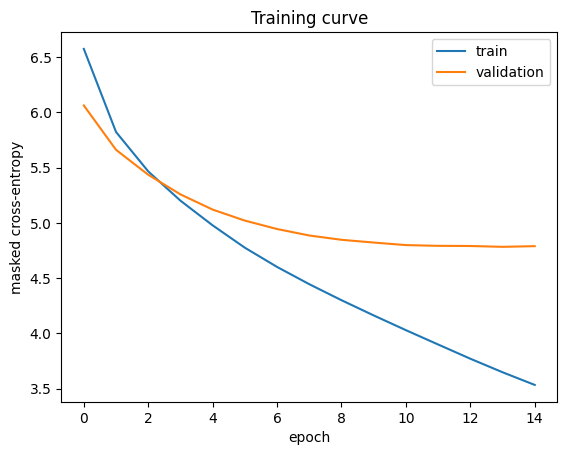

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("epoch"); plt.ylabel("masked cross-entropy"); plt.legend(); plt.title("Training curve")
plt.show()

The graph represents the loss of integrity give the probability of choosing the wrong German word for the sentence. The loss reduce from 6.05 to 4.8 while the model was being evaluated

In [ ]:
# Encoder model: (words, POS) -> (h, c)
enc_model = Model([enc_words_in, enc_pos_in], [enc_h, enc_c])

# One-step decoder model reusing the trained decoder layers
step_tok = layers.Input(shape=(1,), dtype="int32")
step_h   = layers.Input(shape=(UNITS,))
step_c   = layers.Input(shape=(UNITS,))
step_seq, step_h2, step_c2 = dec_lstm(dec_emb(step_tok), initial_state=[step_h, step_c])
dec_model = Model([step_tok, step_h, step_c], [dec_dense(step_seq), step_h2, step_c2])

def beam_search(h, c, width=3):
    beams = [{"toks": [START], "lp": 0.0, "h": h, "c": c, "p": []}]
    finished = []
    for _ in range(MAX_LEN + 1):
        cands = []
        for b in beams:
            probs, h2, c2 = dec_model.predict([np.array([[b["toks"][-1]]]), b["h"], b["c"]], verbose=0)
            probs = probs[0, 0].copy()
            probs[[PAD, UNK, START]] = 0.0           # never emit these tokens
            probs /= probs.sum()
            for t in np.argsort(probs)[-width:][::-1]:
                cands.append({"toks": b["toks"] + [int(t)],
                              "lp": b["lp"] + float(np.log(probs[t] + 1e-12)),
                              "h": h2, "c": c2, "p": b["p"] + [float(probs[t])]})
        cands.sort(key=lambda d: d["lp"], reverse=True)
        beams = []
        for cd in cands[:width]:
            (finished if cd["toks"][-1] == END else beams).append(cd)
        if not beams or len(finished) >= width:
            break
    return finished if finished else beams

def translate(sentence, beam_width=3, top_n=3, show_token_confidence=True):
    clean = clean_text(sentence)
    tokens = clean.split()[:MAX_LEN]
    if not tokens:
        raise ValueError("Please enter a sentence containing at least one word.")
    tags = [t for _, t in pos_tag(tokens, tagset="universal")]
    xw, xp = encode_source(tokens, tags)
    h, c = enc_model.predict([xw[None], xp[None]], verbose=0)

    results = []
    for cd in beam_search(h, c, beam_width):
        words = [de_itos[t] for t in cd["toks"][1:] if t != END]
        n_tok = max(len(cd["p"]), 1)
        results.append({"translation": " ".join(words), "lp": cd["lp"],
                        "sequence_prob": float(np.exp(cd["lp"])),
                        "avg_token_prob": float(np.exp(cd["lp"] / n_tok)),
                        "token_probs": list(zip(words + ["<end>"], cd["p"]))})
    results.sort(key=lambda r: r["avg_token_prob"], reverse=True)
    results = results[:top_n]

    lps = np.array([r["lp"] for r in results])
    shares = np.exp(lps - lps.max()); shares /= shares.sum()
    for r, s in zip(results, shares):
        r["share"] = float(s)

    out = pd.DataFrame(results)[["translation", "sequence_prob", "avg_token_prob", "share"]]
    if show_token_confidence:
        print("Input (cleaned):", clean)
        print("Per-token probability of best translation:")
        print("  " + "  ".join(f"{w}({p:.2f})" for w, p in results[0]["token_probs"]))
    return out

The code above is the translation function.

In [ ]:
examples = [
    "The European Parliament will vote on the proposal tomorrow.",
    "We must protect the rights of all citizens.",
    "I would like to thank the Commission for its report.",
]
for s in examples:
    print("\n" + "=" * 80); print("EN:", s)
    display(translate(s))


EN: The European Parliament will vote on the proposal tomorrow.
Input (cleaned): the european parliament will vote on the proposal tomorrow
Per-token probability of best translation:
  das(0.63)  europäische(0.70)  parlament(0.95)  hat(0.44)  das(0.09)  europäische(0.16)  parlament(0.94)  <end>(0.18)


,translation,sequence_prob,avg_token_prob,share
0,das europäische parlament hat das europäische ...,4.526320e-04,0.381916,0.976420
1,das europäische parlament hat das europäische ...,3.029499e-07,0.286273,0.000654
2,das europäische parlament hat das europäische ...,1.062798e-05,0.280145,0.022927



EN: We must protect the rights of all citizens.
Input (cleaned): we must protect the rights of all citizens
Per-token probability of best translation:
  wir(0.80)  müssen(0.70)  die(0.37)  europäische(0.04)  union(0.72)  nicht(0.08)  zulassen(0.08)  <end>(0.97)


,translation,sequence_prob,avg_token_prob,share
0,wir müssen die europäische union nicht zulassen,0.000034,0.276316,0.648300
1,wir müssen die europäische union nicht unterst...,0.000017,0.252884,0.319081
2,wir müssen die europäische union nicht mehr tun,0.000002,0.228674,0.032619



EN: I would like to thank the Commission for its report.
Input (cleaned): i would like to thank the commission for its report
Per-token probability of best translation:
  ich(0.80)  möchte(0.54)  der(0.20)  kommission(0.51)  für(0.13)  den(0.20)  bericht(0.38)  gestimmt(0.20)  <end>(0.90)


,translation,sequence_prob,avg_token_prob,share
0,ich möchte der kommission für den bericht gest...,8.280287e-05,0.351924,0.983803
1,ich möchte der kommission für den bericht von ...,8.541380e-07,0.280751,0.010148
2,ich möchte der kommission für den bericht von ...,5.091138e-07,0.267850,0.006049


The model is tested using three sample sentences. It is also letting the user know the other probable ways the sentence can be framed

In [ ]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

N_EVAL = 200
refs, hyps = [], []
for i in val_idx[:N_EVAL]:
    best = translate(df.english[i], beam_width=3, top_n=1, show_token_confidence=False).iloc[0]
    hyps.append(best.translation.split())
    refs.append([df.de_tokens[i]])

bleu = corpus_bleu(refs, hyps, smoothing_function=SmoothingFunction().method1)
print(f"BLEU on {N_EVAL} validation sentences: {bleu * 100:.2f}")

BLEU on 200 validation sentences: 3.75


BLEU score

The BLEU evaluation metric scores 3.75, which indicates that the results are not valuable. However, the BLEU score is unreliable as the metric is not designed to evaluate a single sentence.

In [ ]:
model.save("en_de_seq2seq.keras", include_optimizer=False)
with open("en_de_vocab.pkl", "wb") as f:
    pickle.dump({"en_stoi": en_stoi, "en_itos": en_itos, "de_stoi": de_stoi, "de_itos": de_itos,
                 "pos_stoi": pos_stoi, "pos_itos": pos_itos, "MAX_LEN": MAX_LEN}, f)
df.to_pickle("parallel_corpus.pkl")
print("Saved model, vocabularies and DataFrame.")

Saved model, vocabularies and DataFrame.


The model created is saved in a '.pkl' file. The dataframe is also saves as a '.pkl' file.